# Entraînement LightGBM - Credit Scoring

Ce notebook entraîne un modèle LightGBM avec les hyperparamètres optimisés trouvés par optimisation bayésienne (voir `legacy/MLflow.py`).

## Workflow
1. **Chargement des données** : `data/model_dataset.csv`
2. **Preprocessing** : StandardScaler + OneHotEncoder + imputation des NaN
3. **Feature selection** : SelectFromModel avec LightGBM
4. **Entraînement** : LightGBM avec hyperparamètres optimisés
5. **Évaluation** : Métriques avec seuil optimal (G-mean)
6. **Export** : `artifacts/pipeline.joblib` pour déploiement sur Cloud Run

---

## 1. Configuration et imports

In [10]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path
import warnings

from lightgbm import LGBMClassifier
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectFromModel
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import roc_curve, auc, confusion_matrix

# Configuration
pd.set_option('display.max_columns', None)
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# Supprimer les warnings sklearn non critiques
warnings.filterwarnings('ignore', category=UserWarning, module='sklearn')

print("Imports OK")

Imports OK


## 2. Chargement des données

In [12]:
# Chargement du dataset
df = pd.read_csv(
    'data/model_dataset.csv',
    low_memory=False,
    encoding='ISO-8859-1'
)

print(f"Shape: {df.shape}")
print(f"\nTarget distribution:")
print(df['TARGET'].value_counts())
print(f"\nTaux de défaut: {df['TARGET'].mean():.2%}")

df.head()

Shape: (307511, 433)

Target distribution:
TARGET
0    282686
1     24825
Name: count, dtype: int64

Taux de défaut: 8.07%


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,FLOORSMAX_AVG,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_3,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,DAYS_EMPLOYED_PERC,INCOME_CREDIT_PERC,INCOME_PER_PERSON,ANNUITY_INCOME_PERC,PAYMENT_RATE,BURO_DAYS_CREDIT_MIN,BURO_DAYS_CREDIT_MAX,BURO_DAYS_CREDIT_MEAN,BURO_DAYS_CREDIT_VAR,BURO_DAYS_CREDIT_ENDDATE_MIN,BURO_DAYS_CREDIT_ENDDATE_MAX,BURO_DAYS_CREDIT_ENDDATE_MEAN,BURO_DAYS_CREDIT_UPDATE_MEAN,BURO_CREDIT_DAY_OVERDUE_MAX,BURO_CREDIT_DAY_OVERDUE_MEAN,BURO_AMT_CREDIT_MAX_OVERDUE_MEAN,BURO_AMT_CREDIT_SUM_MAX,BURO_AMT_CREDIT_SUM_MEAN,BURO_AMT_CREDIT_SUM_SUM,BURO_AMT_CREDIT_SUM_DEBT_MAX,BURO_AMT_CREDIT_SUM_DEBT_MEAN,BURO_AMT_CREDIT_SUM_OVERDUE_MEAN,BURO_AMT_CREDIT_SUM_LIMIT_MEAN,BURO_AMT_CREDIT_SUM_LIMIT_SUM,BURO_CNT_CREDIT_PROLONG_SUM,BURO_MONTHS_BALANCE_SIZE_MEAN,BURO_MONTHS_BALANCE_SIZE_SUM,BURO_CREDIT_ACTIVE_Active_MEAN,BURO_CREDIT_ACTIVE_Bad debt_MEAN,BURO_CREDIT_ACTIVE_Sold_MEAN,BURO_CREDIT_CURRENCY_currency 1_MEAN,BURO_CREDIT_CURRENCY_currency 3_MEAN,BURO_CREDIT_CURRENCY_currency 4_MEAN,BURO_CREDIT_TYPE_Another type of loan_MEAN,BURO_CREDIT_TYPE_Car loan_MEAN,BURO_CREDIT_TYPE_Cash loan (non-earmarked)_MEAN,BURO_CREDIT_TYPE_Consumer credit_MEAN,BURO_CREDIT_TYPE_Credit card_MEAN,BURO_CREDIT_TYPE_Interbank credit_MEAN,BURO_CREDIT_TYPE_Loan for business development_MEAN,BURO_CREDIT_TYPE_Loan for purchase of shares (margin lending)_MEAN,BURO_CREDIT_TYPE_Loan for the purchase of equipment_MEAN,BURO_CREDIT_TYPE_Loan for working capital replenishment_MEAN,BURO_CREDIT_TYPE_Microloan_MEAN,BURO_CREDIT_TYPE_Mobile operator loan_MEAN,BURO_CREDIT_TYPE_Mortgage_MEAN,BURO_CREDIT_TYPE_Real estate loan_MEAN,BURO_CREDIT_TYPE_Unknown type of loan_MEAN,BURO_STATUS_1_MEAN_MEAN,ACTIVE_DAYS_CREDIT_MIN,ACTIVE_DAYS_CREDIT_MAX,ACTIVE_DAYS_CREDIT_MEAN,ACTIVE_DAYS_CREDIT_ENDDATE_MIN,ACTIVE_DAYS_CREDIT_ENDDATE_MEAN,ACTIVE_DAYS_CREDIT_UPDATE_MEAN,ACTIVE_CREDIT_DAY_OVERDUE_MEAN,ACTIVE_AMT_CREDIT_SUM_MAX,ACTIVE_AMT_CREDIT_SUM_MEAN,ACTIVE_AMT_CREDIT_SUM_DEBT_MEAN,ACTIVE_AMT_CREDIT_SUM_OVERDUE_MEAN,ACTIVE_AMT_CREDIT_SUM_LIMIT_MEAN,ACTIVE_CNT_CREDIT_PROLONG_SUM,ACTIVE_MONTHS_BALANCE_SIZE_SUM,CLOSED_DAYS_CREDIT_MAX,CLOSED_DAYS_CREDIT_MEAN,CLOSED_DAYS_CREDIT_VAR,CLOSED_DAYS_CREDIT_ENDDATE_MIN,CLOSED_DAYS_CREDIT_ENDDATE_MAX,CLOSED_DAYS_CREDIT_ENDDATE_MEAN,CLOSED_DAYS_CREDIT_UPDATE_MEAN,CLOSED_CREDIT_DAY_OVERDUE_MAX,CLOSED_CREDIT_DAY_OVERDUE_MEAN,CLOSED_AMT_CREDIT_SUM_MAX,CLOSED_AMT_CREDIT_SUM_MEAN,CLOSED_AMT_CREDIT_SUM_SUM,CLOSED_AMT_CREDIT_SUM_DEBT_MAX,CLOSED_AMT_CREDIT_SUM_DEBT_MEAN,CLOSED_AMT_CREDIT_SUM_OVERDUE_MEAN,CLOSED_AMT_CREDIT_SUM_LIMIT_MEAN,CLOSED_AMT_CREDIT_SUM_LIMIT_SUM,CLOSED_CNT_CREDIT_PROLONG_SUM,PREV_AMT_ANNUITY_MIN,PREV_AMT_ANNUITY_MAX,PREV_AMT_ANNUITY_MEAN,PREV_AMT_APPLICATION_MIN,PREV_AMT_APPLICATION_MAX,PREV_AMT_APPLICATION_MEAN,PREV_APP_CREDIT_PERC_MIN,PREV_APP_CREDIT_PERC_MAX,PREV_APP_CREDIT_PERC_MEAN,PREV_APP_CREDIT_PERC_VAR,PREV_AMT_DOWN_PAYMENT_MIN,PREV_AMT_DOWN_PAYMENT_MAX,PREV_AMT_DOWN_PAYMENT_MEAN,PREV_AMT_GOODS_PRICE_MIN,PREV_HOUR_APPR_PROCESS_START_MIN,PREV_HOUR_APPR_PROCESS_START_MAX,PREV_HOUR_APPR

## 3. Preprocessing

In [13]:
# Remplacer les valeurs infinies par NaN
df = df.replace([np.inf, -np.inf], np.nan)

# Supprimer SK_ID_CURR (identifiant client)
if 'SK_ID_CURR' in df.columns:
    df = df.drop(columns=['SK_ID_CURR'])

# Séparer features et target
X = df.drop(columns=['TARGET'])
y = df['TARGET']

print(f"Features: {X.shape[1]}")
print(f"Target: {y.shape}")

# Identifier les colonnes numériques et catégorielles
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print(f"\nNumériques: {len(numeric_features)}")
print(f"Catégorielles: {len(categorical_features)}")

Features: 431
Target: (307511,)

Numériques: 422
Catégorielles: 9


In [14]:
# Créer les transformers
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Assembler le preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessor créé")

Preprocessor créé


## 4. Feature Selection + Modèle LightGBM

**Hyperparamètres optimisés** (trouvés par optimisation bayésienne dans `legacy/MLflow.py`):
- `n_estimators=1000`
- `learning_rate=0.02`
- `max_depth=9`
- `num_leaves=44`
- `scale_pos_weight=11.39` → gère le déséquilibre des classes (8% de défauts)

In [15]:
# Feature selector avec LightGBM
selector = SelectFromModel(LGBMClassifier(n_jobs=-1, random_state=123))

# Classifieur LightGBM avec hyperparamètres optimisés
clf = LGBMClassifier(
    n_estimators=1000,
    learning_rate=0.02,
    num_leaves=44,
    colsample_bytree=0.235,
    subsample=0.150,
    max_depth=9,
    reg_alpha=0.647,
    reg_lambda=0.884,
    min_split_gain=0.773,
    min_child_weight=34.7,
    scale_pos_weight=11.39,  # Important pour gérer le déséquilibre
    random_state=123,
    verbose=-1
)

# Pipeline complet
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('selector', selector),
    ('classifier', clf)
])

print("Pipeline créé")
print(pipeline)

Pipeline créé
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['CODE_GENDER',
                                                   'FLAG_OWN_CAR',
                                                   'FLAG_OWN_REALTY',
                                                   'CNT_CHILDREN',
                                                   'AMT_INCOME_TOTAL',
                                                   'AMT_CREDIT', 'AMT_ANNUITY',
                                                   'AMT_GOODS_PRICE',
                                                   'REGION_P

## 5. Train/Test Split et Entraînement

In [16]:
# Split train/test (stratifié pour conserver la distribution de TARGET)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=123,
    stratify=y
)

print(f"Train: {X_train.shape}")
print(f"Test: {X_test.shape}")
print(f"\nDistribution train: {y_train.value_counts().to_dict()}")
print(f"Distribution test: {y_test.value_counts().to_dict()}")

Train: (246008, 431)
Test: (61503, 431)

Distribution train: {0: 226148, 1: 19860}
Distribution test: {0: 56538, 1: 4965}


In [9]:
X_train.head()

,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,FLOORSMAX_AVG,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_3,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,DAYS_EMPLOYED_PERC,INCOME_CREDIT_PERC,INCOME_PER_PERSON,ANNUITY_INCOME_PERC,PAYMENT_RATE,BURO_DAYS_CREDIT_MIN,BURO_DAYS_CREDIT_MAX,BURO_DAYS_CREDIT_MEAN,BURO_DAYS_CREDIT_VAR,BURO_DAYS_CREDIT_ENDDATE_MIN,BURO_DAYS_CREDIT_ENDDATE_MAX,BURO_DAYS_CREDIT_ENDDATE_MEAN,BURO_DAYS_CREDIT_UPDATE_MEAN,BURO_CREDIT_DAY_OVERDUE_MAX,BURO_CREDIT_DAY_OVERDUE_MEAN,BURO_AMT_CREDIT_MAX_OVERDUE_MEAN,BURO_AMT_CREDIT_SUM_MAX,BURO_AMT_CREDIT_SUM_MEAN,BURO_AMT_CREDIT_SUM_SUM,BURO_AMT_CREDIT_SUM_DEBT_MAX,BURO_AMT_CREDIT_SUM_DEBT_MEAN,BURO_AMT_CREDIT_SUM_OVERDUE_MEAN,BURO_AMT_CREDIT_SUM_LIMIT_MEAN,BURO_AMT_CREDIT_SUM_LIMIT_SUM,BURO_CNT_CREDIT_PROLONG_SUM,BURO_MONTHS_BALANCE_SIZE_MEAN,BURO_MONTHS_BALANCE_SIZE_SUM,BURO_CREDIT_ACTIVE_Active_MEAN,BURO_CREDIT_ACTIVE_Bad debt_MEAN,BURO_CREDIT_ACTIVE_Sold_MEAN,BURO_CREDIT_CURRENCY_currency 1_MEAN,BURO_CREDIT_CURRENCY_currency 3_MEAN,BURO_CREDIT_CURRENCY_currency 4_MEAN,BURO_CREDIT_TYPE_Another type of loan_MEAN,BURO_CREDIT_TYPE_Car loan_MEAN,BURO_CREDIT_TYPE_Cash loan (non-earmarked)_MEAN,BURO_CREDIT_TYPE_Consumer credit_MEAN,BURO_CREDIT_TYPE_Credit card_MEAN,BURO_CREDIT_TYPE_Interbank credit_MEAN,BURO_CREDIT_TYPE_Loan for business development_MEAN,BURO_CREDIT_TYPE_Loan for purchase of shares (margin lending)_MEAN,BURO_CREDIT_TYPE_Loan for the purchase of equipment_MEAN,BURO_CREDIT_TYPE_Loan for working capital replenishment_MEAN,BURO_CREDIT_TYPE_Microloan_MEAN,BURO_CREDIT_TYPE_Mobile operator loan_MEAN,BURO_CREDIT_TYPE_Mortgage_MEAN,BURO_CREDIT_TYPE_Real estate loan_MEAN,BURO_CREDIT_TYPE_Unknown type of loan_MEAN,BURO_STATUS_1_MEAN_MEAN,ACTIVE_DAYS_CREDIT_MIN,ACTIVE_DAYS_CREDIT_MAX,ACTIVE_DAYS_CREDIT_MEAN,ACTIVE_DAYS_CREDIT_ENDDATE_MIN,ACTIVE_DAYS_CREDIT_ENDDATE_MEAN,ACTIVE_DAYS_CREDIT_UPDATE_MEAN,ACTIVE_CREDIT_DAY_OVERDUE_MEAN,ACTIVE_AMT_CREDIT_SUM_MAX,ACTIVE_AMT_CREDIT_SUM_MEAN,ACTIVE_AMT_CREDIT_SUM_DEBT_MEAN,ACTIVE_AMT_CREDIT_SUM_OVERDUE_MEAN,ACTIVE_AMT_CREDIT_SUM_LIMIT_MEAN,ACTIVE_CNT_CREDIT_PROLONG_SUM,ACTIVE_MONTHS_BALANCE_SIZE_SUM,CLOSED_DAYS_CREDIT_MAX,CLOSED_DAYS_CREDIT_MEAN,CLOSED_DAYS_CREDIT_VAR,CLOSED_DAYS_CREDIT_ENDDATE_MIN,CLOSED_DAYS_CREDIT_ENDDATE_MAX,CLOSED_DAYS_CREDIT_ENDDATE_MEAN,CLOSED_DAYS_CREDIT_UPDATE_MEAN,CLOSED_CREDIT_DAY_OVERDUE_MAX,CLOSED_CREDIT_DAY_OVERDUE_MEAN,CLOSED_AMT_CREDIT_SUM_MAX,CLOSED_AMT_CREDIT_SUM_MEAN,CLOSED_AMT_CREDIT_SUM_SUM,CLOSED_AMT_CREDIT_SUM_DEBT_MAX,CLOSED_AMT_CREDIT_SUM_DEBT_MEAN,CLOSED_AMT_CREDIT_SUM_OVERDUE_MEAN,CLOSED_AMT_CREDIT_SUM_LIMIT_MEAN,CLOSED_AMT_CREDIT_SUM_LIMIT_SUM,CLOSED_CNT_CREDIT_PROLONG_SUM,PREV_AMT_ANNUITY_MIN,PREV_AMT_ANNUITY_MAX,PREV_AMT_ANNUITY_MEAN,PREV_AMT_APPLICATION_MIN,PREV_AMT_APPLICATION_MAX,PREV_AMT_APPLICATION_MEAN,PREV_APP_CREDIT_PERC_MIN,PREV_APP_CREDIT_PERC_MAX,PREV_APP_CREDIT_PERC_MEAN,PREV_APP_CREDIT_PERC_VAR,PREV_AMT_DOWN_PAYMENT_MIN,PREV_AMT_DOWN_PAYMENT_MAX,PREV_AMT_DOWN_PAYMENT_MEAN,PREV_AMT_GOODS_PRICE_MIN,PREV_HOUR_APPR_PROCESS_START_MIN,PREV_HOUR_APPR_PROCESS_START_MAX,PREV_HOUR_APPR_PROCESS_START_MEA

In [17]:
%%time
# Entraînement du pipeline complet
print("Entraînement en cours...")
pipeline.fit(X_train, y_train)
print("Entraînement terminé !")

Entraînement en cours...
Entraînement terminé !
CPU times: user 59.9 s, sys: 44.6 s, total: 1min 44s
Wall time: 24.3 s
Entraînement terminé !
CPU times: user 59.9 s, sys: 44.6 s, total: 1min 44s
Wall time: 24.3 s


## 6. Évaluation du modèle

In [18]:
# Prédictions sur le test set
y_proba = pipeline.predict_proba(X_test)[:, 1]

# Calcul de la courbe ROC
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

# Calcul du G-mean pour trouver le seuil optimal
g_means = np.sqrt(tpr * (1 - fpr))
ix = np.argmax(g_means)
optimal_threshold = thresholds[ix]
optimal_gmean = g_means[ix]

print(f"AUC: {roc_auc:.4f}")
print(f"Seuil optimal (G-mean): {optimal_threshold:.4f}")
print(f"G-mean optimal: {optimal_gmean:.4f}")

# Prédictions avec seuil optimal
y_pred = (y_proba >= optimal_threshold).astype(int)

# Matrice de confusion
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print(f"\nMatrice de confusion:")
print(f"TN={tn}, FP={fp}")
print(f"FN={fn}, TP={tp}")

# Métriques
accuracy = (tp + tn) / (tp + tn + fp + fn)
recall = tp / (tp + fn) if (tp + fn) > 0 else 0
precision = tp / (tp + fp) if (tp + fp) > 0 else 0
f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

print(f"\nMétriques:")
print(f"Accuracy: {accuracy:.4f}")
print(f"Recall: {recall:.4f}")
print(f"Precision: {precision:.4f}")
print(f"F1-score: {f1:.4f}")

AUC: 0.7865
Seuil optimal (G-mean): 0.4751
G-mean optimal: 0.7176

Matrice de confusion:
TN=41769, FP=14769
FN=1504, TP=3461

Métriques:
Accuracy: 0.7354
Recall: 0.6971
Precision: 0.1899
F1-score: 0.2984


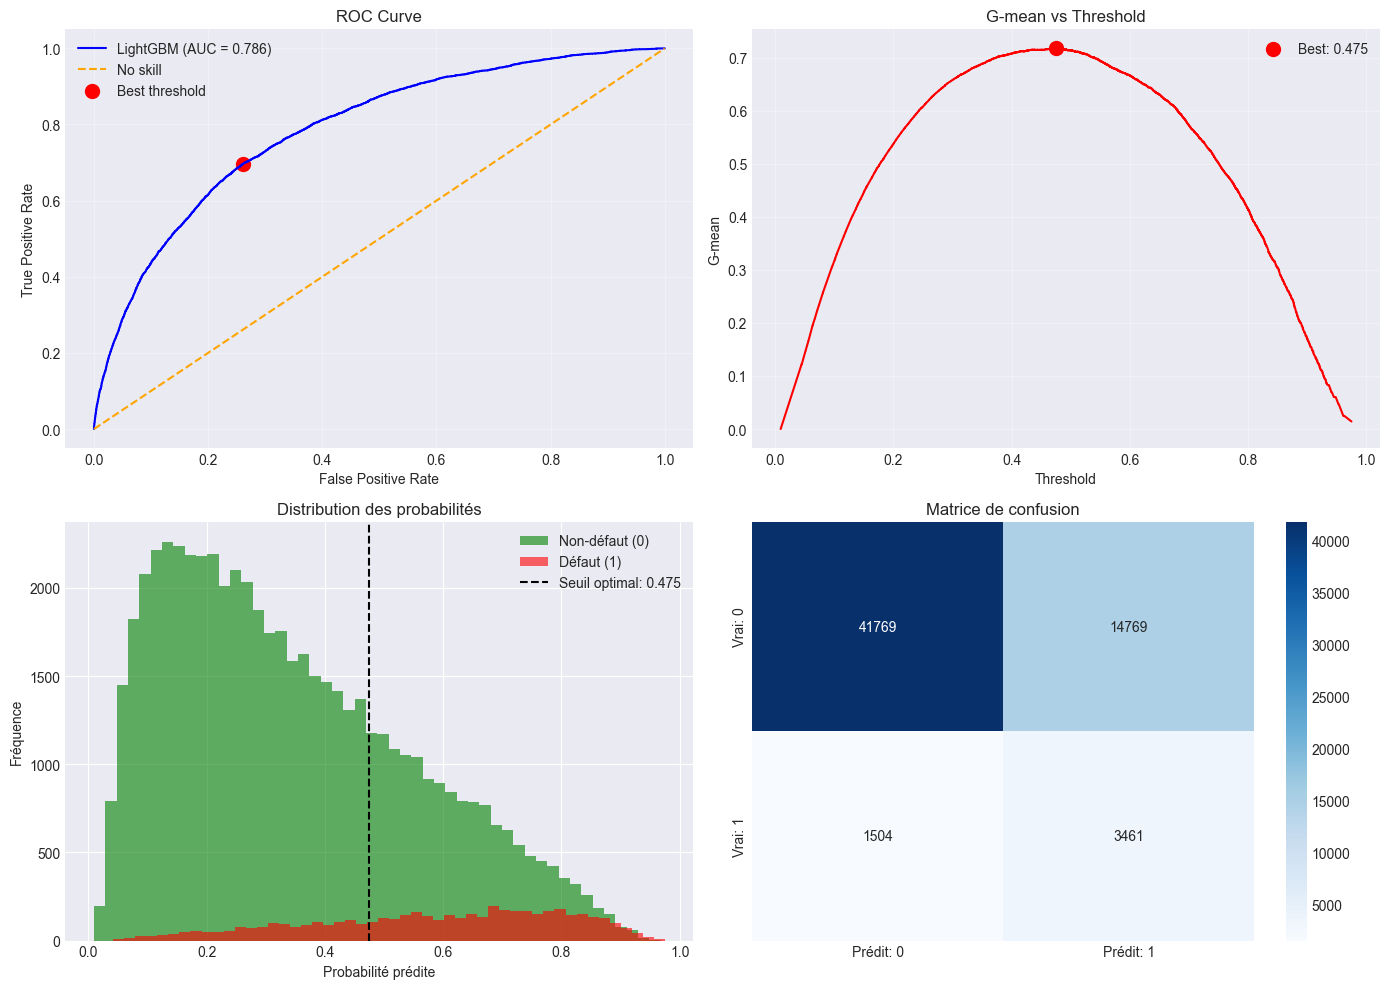

Graphiques sauvegardés: artifacts/evaluation.png


In [19]:
# Visualisations
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Courbe ROC
axes[0, 0].plot(fpr, tpr, label=f'LightGBM (AUC = {roc_auc:.3f})', color='blue')
axes[0, 0].plot([0, 1], [0, 1], '--', color='orange', label='No skill')
axes[0, 0].scatter(fpr[ix], tpr[ix], marker='o', s=100, color='red', label='Best threshold')
axes[0, 0].set_xlabel('False Positive Rate')
axes[0, 0].set_ylabel('True Positive Rate')
axes[0, 0].set_title('ROC Curve')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# 2. G-mean vs Threshold
axes[0, 1].plot(thresholds, g_means, 'r')
axes[0, 1].scatter(thresholds[ix], g_means[ix], marker='o', s=100, color='red', label=f'Best: {optimal_threshold:.3f}')
axes[0, 1].set_xlabel('Threshold')
axes[0, 1].set_ylabel('G-mean')
axes[0, 1].set_title('G-mean vs Threshold')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# 3. Distribution des probabilités prédites
axes[1, 0].hist(y_proba[y_test == 0], bins=50, alpha=0.6, label='Non-défaut (0)', color='green')
axes[1, 0].hist(y_proba[y_test == 1], bins=50, alpha=0.6, label='Défaut (1)', color='red')
axes[1, 0].axvline(optimal_threshold, color='black', linestyle='--', label=f'Seuil optimal: {optimal_threshold:.3f}')
axes[1, 0].set_xlabel('Probabilité prédite')
axes[1, 0].set_ylabel('Fréquence')
axes[1, 0].set_title('Distribution des probabilités')
axes[1, 0].legend()

# 4. Matrice de confusion
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1, 1],
            xticklabels=['Prédit: 0', 'Prédit: 1'],
            yticklabels=['Vrai: 0', 'Vrai: 1'])
axes[1, 1].set_title('Matrice de confusion')

plt.tight_layout()
plt.savefig('artifacts/evaluation.png', dpi=150, bbox_inches='tight')
plt.show()

print("Graphiques sauvegardés: artifacts/evaluation.png")

## 7. Feature Importance

In [20]:
# Récupérer les feature importances
importances = pipeline.named_steps['classifier'].feature_importances_

# Récupérer les noms de features après preprocessing et sélection
pre = pipeline.named_steps['preprocessor']
cat_cols = pre.transformers_[1][2] if len(pre.transformers_) > 1 else []
if len(cat_cols) > 0:
    cat_names = list(pre.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(cat_cols))
else:
    cat_names = []
num_names = list(pre.transformers_[0][2])
all_names = num_names + cat_names

selector = pipeline.named_steps['selector']
support = selector.get_support()
selected_names = [n for n, keep in zip(all_names, support) if keep]

# DataFrame avec importances
feat_df = pd.DataFrame({
    'feature': selected_names,
    'importance': importances
}).sort_values('importance', ascending=False)

print(f"Nombre de features sélectionnées: {len(selected_names)}")
print(f"\nTop 20 features les plus importantes:")
print(feat_df.head(20))

# Sauvegarder
feat_df.to_csv('artifacts/feature_importance.csv', index=False)
print("\nSauvegardé: artifacts/feature_importance.csv")

Nombre de features sélectionnées: 146

Top 20 features les plus importantes:
                       feature  importance
28                PAYMENT_RATE        1410
16                EXT_SOURCE_2         906
15                EXT_SOURCE_1         822
7                   DAYS_BIRTH         790
17                EXT_SOURCE_3         737
3                   AMT_CREDIT         631
4                  AMT_ANNUITY         609
5              AMT_GOODS_PRICE         554
10             DAYS_ID_PUBLISH         545
125  INSTAL_AMT_INSTALMENT_SUM         510
9            DAYS_REGISTRATION         500
25          INCOME_CREDIT_PERC         481
84       PREV_CNT_PAYMENT_MEAN         480
106  APPROVED_CNT_PAYMENT_MEAN         465
21      DAYS_LAST_PHONE_CHANGE         464
110    POS_MONTHS_BALANCE_SIZE         461
24          DAYS_EMPLOYED_PERC         458
119             INSTAL_DBD_SUM         456
49      ACTIVE_DAYS_CREDIT_MAX         455
30        BURO_DAYS_CREDIT_MAX         444

Sauvegardé: artifac

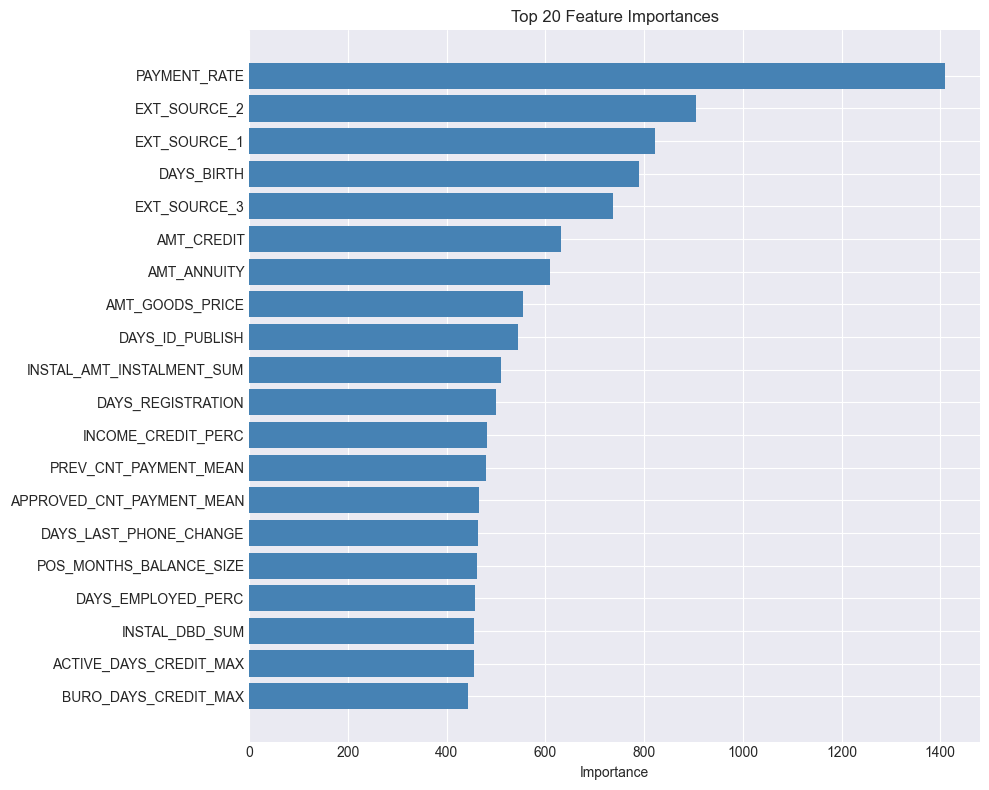

Graphique sauvegardé: artifacts/feature_importance.png


In [21]:
# Visualisation des top 20 features
plt.figure(figsize=(10, 8))
top_20 = feat_df.head(20)
plt.barh(range(len(top_20)), top_20['importance'].values, color='steelblue')
plt.yticks(range(len(top_20)), top_20['feature'].values)
plt.xlabel('Importance')
plt.title('Top 20 Feature Importances')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('artifacts/feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print("Graphique sauvegardé: artifacts/feature_importance.png")

## 8. Export du modèle pour déploiement

In [22]:
# Créer le dossier artifacts s'il n'existe pas
Path('artifacts').mkdir(exist_ok=True)

# Sauvegarder le pipeline complet
joblib.dump(pipeline, 'artifacts/pipeline.joblib')
print("Pipeline sauvegardé: artifacts/pipeline.joblib")

# Sauvegarder les métriques
metrics = {
    'threshold': float(optimal_threshold),
    'accuracy': float(accuracy),
    'recall': float(recall),
    'precision': float(precision),
    'f1': float(f1),
    'gmean': float(optimal_gmean),
    'roc_auc': float(roc_auc),
    'confusion_matrix': {
        'tn': int(tn),
        'fp': int(fp),
        'fn': int(fn),
        'tp': int(tp)
    }
}

import json
with open('artifacts/metrics.json', 'w') as f:
    json.dump(metrics, f, indent=2)

print("Métriques sauvegardées: artifacts/metrics.json")
print("\n" + "="*50)
print("ENTRAÎNEMENT TERMINÉ !")
print("="*50)

Pipeline sauvegardé: artifacts/pipeline.joblib
Métriques sauvegardées: artifacts/metrics.json

ENTRAÎNEMENT TERMINÉ !


## 9. Test du pipeline

Testons le pipeline rechargé pour vérifier qu'il fonctionne correctement.

In [23]:
# Recharger le pipeline
loaded_pipeline = joblib.load('artifacts/pipeline.joblib')

# Tester sur un échantillon
sample = X_test.iloc[:5]
predictions = loaded_pipeline.predict_proba(sample)[:, 1]

print("Test du pipeline rechargé:")
for i, prob in enumerate(predictions):
    decision = "ACCEPTÉ" if prob < optimal_threshold else "REFUSÉ"
    print(f"  Client {i+1}: Proba défaut = {prob:.4f} → {decision}")

print("\nPipeline OK ! Prêt pour le déploiement.")

Test du pipeline rechargé:
  Client 1: Proba défaut = 0.6064 → REFUSÉ
  Client 2: Proba défaut = 0.1316 → ACCEPTÉ
  Client 3: Proba défaut = 0.5869 → REFUSÉ
  Client 4: Proba défaut = 0.0837 → ACCEPTÉ
  Client 5: Proba défaut = 0.7631 → REFUSÉ

Pipeline OK ! Prêt pour le déploiement.
